# Notebook 04 — Componente no supervisado: segmentación de visitantes

**Problema:** descubrir **tipos de visitantes según cómo navegan**, sin usar `Revenue`. Es una pregunta distinta a la del notebook 03: allí se predice *un resultado conocido*; aquí se busca *estructura que no sabíamos que existía*.

**Reglas de diseño**
1. **`Revenue` no entra al agrupamiento** (requisito del enunciado). Solo se usa *después*, para interpretar los grupos.
2. Se usan solo **variables de conducta de navegación** (páginas visitadas, duraciones, tasas de rebote y salida). Se **excluye `PageValues`** por contener información del resultado (notebook 01) y `SpecialDay` por ser un dato de calendario, no de conducta.
3. No hay conjunto de prueba: el agrupamiento no predice, describe. El escalador se ajusta con todas las sesiones porque no se usa ninguna etiqueta.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sys.path.insert(0, str(RAIZ / 'src'))
from preprocesamiento import (cargar_datos, dividir_train_test, construir_preprocesador, matriz_conducta,
                              NUMERICAS, CATEGORICAS, BINARIAS, CONDUCTA, OBJETIVO, SEMILLA, MESES_ORDEN)

In [2]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score

df = cargar_datos()
X, escala = matriz_conducta(df)           # log1p + estandarizacion de las 8 variables de conducta
print(f'{X.shape[0]:,} sesiones x {X.shape[1]} variables de conducta:', CONDUCTA)

12,205 sesiones x 8 variables de conducta: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']


## 1. Algoritmos seleccionados y por qué

| Algoritmo | Idea | Supuestos | Ventajas | Limitaciones aquí |
|---|---|---|---|---|
| **K-Means** | Agrupa por cercanía a un centroide | Grupos **esféricos y de tamaño parecido**; requiere elegir *k* | Rápido, simple, interpretable | Sensible a atípicos y escala; no admite grupos alargados |
| **Gaussian Mixture (GMM)** | Cada grupo es una **distribución normal** con su propia forma; asignación **probabilística** | Los datos vienen de una mezcla de normales | Grupos elípticos de distinto tamaño; da incertidumbre de pertenencia | Más parámetros; sensible a inicialización; las colas largas violan la normalidad |
| **Aglomerativo (Ward)** | Une sesiones de abajo hacia arriba minimizando la varianza interna | Distancia euclídea; no necesita inicialización | Determinista, no depende de la semilla, produce un dendrograma | Costo cuadrático en memoria; no reasigna errores tempranos |

Se comparan los **tres** (mínimo exigido: dos) porque cada uno asume una "forma" distinta de grupo: si los tres encuentran estructura parecida, la estructura es robusta.

## 2. Métricas de calidad del agrupamiento

| Métrica | Qué mide | Mejor |
|---|---|---|
| **Silhouette** | Qué tan cerca está cada sesión de su grupo frente al grupo vecino (−1 a 1) | Más alta |
| **Davies-Bouldin** | Razón entre dispersión interna y separación entre grupos | **Más baja** |
| **Calinski-Harabasz** | Razón entre dispersión entre grupos e interna | Más alta |

## 3. K-Means: ¿cuántos grupos (k)?
Se prueban de 2 a 8 grupos y se miran **inercia (codo)**, **silhouette**, **Davies-Bouldin** y **Calinski-Harabasz**. Ninguna métrica decide sola: se busca un k donde coincidan varias y donde los grupos sean **interpretables para el negocio**.

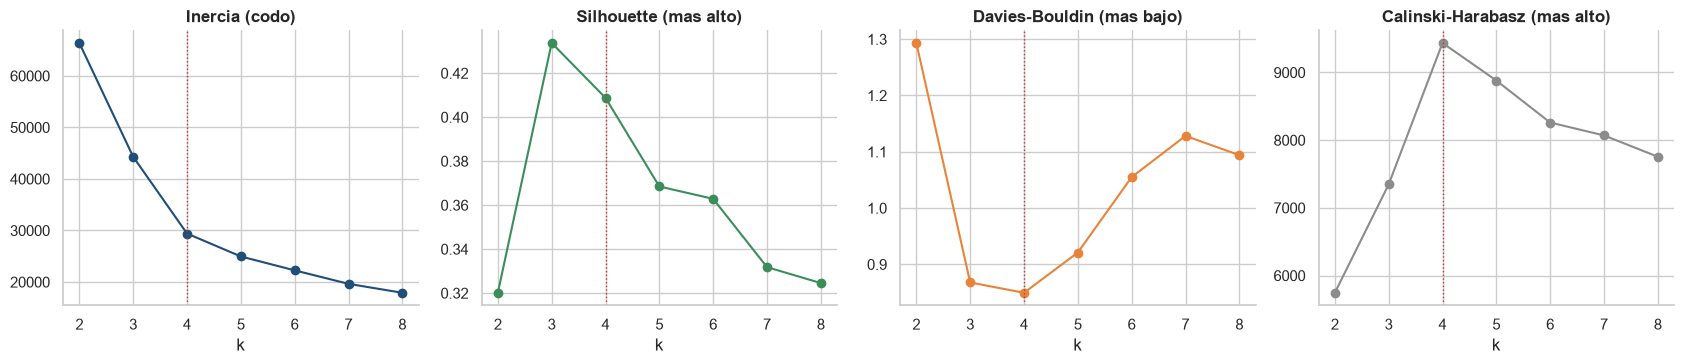

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"66,384.923",0.320,1.293,"5,745.374"
3,"44,298.258",0.434,0.868,"7,346.522"
4,"29,408.017",0.409,0.850,"9,436.184"
5,"24,960.617",0.368,0.921,"8,880.876"
6,"22,263.415",0.363,1.055,"8,260.368"
7,"19,647.066",0.332,1.128,"8,070.400"
8,"17,913.178",0.325,1.094,"7,755.098"


In [3]:
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    filas.append({'k': k, 'inercia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                  'davies_bouldin': davies_bouldin_score(X, km.labels_), 'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
sel_k = pd.DataFrame(filas).set_index('k')

fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col, tit, c in zip(axs, ['inercia', 'silhouette', 'davies_bouldin', 'calinski_harabasz'],
                           ['Inercia (codo)', 'Silhouette (mas alto)', 'Davies-Bouldin (mas bajo)', 'Calinski-Harabasz (mas alto)'],
                           [AZUL, VERDE, NARANJA, GRIS]):
    ax.plot(sel_k.index, sel_k[col], marker='o', color=c); ax.set_title(tit); ax.set_xlabel('k')
    ax.axvline(4, color=ROJO, ls=':', lw=1)
plt.tight_layout()
plt.savefig(FIG / '04_kmeans_seleccion_k.png', dpi=150, bbox_inches='tight')
plt.show()
sel_k

**Elección de k = 4**

| k | Inercia | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|
| 2 | 66.385 | 0,320 | 1,293 | 5.745 |
| 3 | 44.298 | **0,434** | 0,868 | 7.347 |
| **4** | 29.408 | 0,409 | **0,850** | **9.436** |
| 5 | 24.961 | 0,368 | 0,921 | 8.881 |

- **Silhouette** es máximo en k = 3 (0,434) pero k = 4 queda muy cerca (0,409). **Davies-Bouldin es mínimo y Calinski-Harabasz máximo en k = 4**: dos de tres métricas favorecen k = 4.
- El **codo** de la inercia es suave (no hay un quiebre nítido): después de k = 4 las mejoras se hacen cada vez menores.
- Con k = 3 se fusionan visitantes de perfiles distintos; k = 4 separa un grupo pequeño muy diferenciado (los que rebotan) y grupos interpretables. **Se elige k = 4 por consenso de las métricas y por interpretabilidad**, reconociendo que k = 3 es una alternativa válida.
- Un silhouette de 0,41 indica una **estructura razonable pero no excelente** (>0,5 sería fuerte): los grupos se tocan en los bordes.